In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# constants 
gamma=5/3
G=1
M=1
rho_inf=1
cs_inf=1

In [3]:
# Domain construction 
rmin= float(input("Enter the minimum radius: "))
rmax= float(input("Enter the maximum radius: "))
N= int(input ("Enter the number of points: "))
dr= (rmax-rmin)/N
# cell centers
r= np.linspace(rmin+dr/2, rmax-dr/2, N)
# faces 
# they are important as we will use them to compute the fluxes at the cell boundaries of bondi accretion 
rf= np.linspace(rmin, rmax, N+1)
A=4*np.pi*rf**2 #   area of the faces 
vol=4/3*np.pi*(rf[1:]**3-rf[:-1]**3) #   volume of the cells

In [4]:
# Intial conditions
rho= np.ones(N)*rho_inf
u=-0.01*np.ones(N)
p= np.ones(N)*rho_inf*cs_inf**2/gamma
E=(p/(gamma-1))+0.5*rho*u**2
U=np.zeros((3, N))
U[0]=rho
U[1]=rho*u
U[2]=E

In [5]:
# First function to retain the primitive variables from the conserved variables
def Initial_variables(U):
    rho=U[0]
    u=U[1]/rho
    E=U[2]
    p=(gamma-1)*(E-0.5*rho*u**2)
    return rho, u, p

In [6]:
# function to compute the fluxes at the cell boundaries
def flux(U):
    rho, u, p= Initial_variables(U)
    F=np.zeros_like(U)
    F[0]=rho*u
    F[1]=(rho*u**2+p)
    F[2]=(U[2]+p)*u
    return F

In [7]:
# scheme for flux 
def HLLC(Ul, Ur):
    rhol, ul, pl= Initial_variables(Ul)
    rhor, ur, pr= Initial_variables(Ur)
    ## fluxes 
    Fl=flux(Ul)
    Fr=flux(Ur)
    ## energy 
    El=Ul[2]
    Er=Ur[2]
    # speed of sound
    cl= np.sqrt(gamma*pl/rhol)
    cr= np.sqrt(gamma*pr/rhor)

    # wave speed 
    Sl= np.minimum(ul-cl, ur-cr)
    sr= np.maximum(ul+cl, ur+cr)

    # contact wave speed
    Sstar= (pr-pl+ rhol*ul*(Sl-ul)-rhor*ur*(sr-ur))/(rhol*(Sl-ul)-rhor*(sr-ur))

    # flux formulation 
    if Sl>=0:
        return Fl
    elif Sl<=0 and Sstar>=0:
        Ustar_l= rhol*(Sl-ul)/(Sl-Sstar)*np.array([1, Sstar, El/rhol+(Sstar-ul)*(Sstar+pl/(rhol*(Sl-ul)))])
        Fstar_l= Fl+Sl*(Ustar_l-Ul)
        return Fstar_l
    elif Sstar<=0 and sr>=0:
        Ustar_r= rhor*(sr-ur)/(sr-Sstar)*np.array([1, Sstar, Er/rhor+(Sstar-ur)*(Sstar+pr/(rhor*(sr-ur)))])
        Fstar_r= Fr+sr*(Ustar_r-Ur)
        return Fstar_r  
    else:
        return Fr
    


In [8]:
rho_floor = 1e-6
p_floor   = 1e-6
g_all = -G*M/r**2                       # gravity at every cell center
# ambient state for the outer boundary (conserved variables)
U_amb = np.array([rho_inf, 0.0, rho_inf*cs_inf**2/gamma/(gamma-1)])

In [9]:
CFL = 0.4
t = 0.0
t_end = 0.2

while t < t_end:
    rho, u, p = Initial_variables(U)
    a = np.sqrt(gamma*p/rho)
    dt = CFL * (dr/np.max(np.abs(u)+a))
    dt = min(dt, 0.1*np.sqrt(dr/np.max(np.abs(g_all))))     # gravity limit on dt
    if t + dt > t_end:
        dt = t_end - t

    F_interface = np.zeros((3, N+1))
    for i in range(1, N):
        F_interface[:, i] = HLLC(U[:, i-1], U[:, i])

    U_new = U.copy()
    for i in range(1, N-1):
        g = g_all[i]
        S = np.array([0.0,
                      rho[i]*g + p[i]*(A[i+1]-A[i])/vol[i],  # add geometric pressure term
                      rho[i]*u[i]*g])
        U_new[:, i] = U[:, i] - (dt/vol[i])*(A[i+1]*F_interface[:, i+1] - A[i]*F_interface[:, i]) + dt*S

    U_new[:, 0]  = U_new[:, 1]                               # inner: zero-gradient (outflow)
    U_new[:, -1] = U_amb                                     # outer: fixed ambient state

    # CHANGE 4: floors so p and rho can't go negative
    U_new[0] = np.maximum(U_new[0], rho_floor)
    kin = 0.5*U_new[1]**2/U_new[0]
    U_new[2] = np.maximum(U_new[2], kin + p_floor/(gamma-1))

    # CHANGE 5: stop loudly instead of silently
    if not np.all(np.isfinite(U_new)):
        raise RuntimeError(f"NaN at t={t:.4f}")

    U = U_new
    t += dt

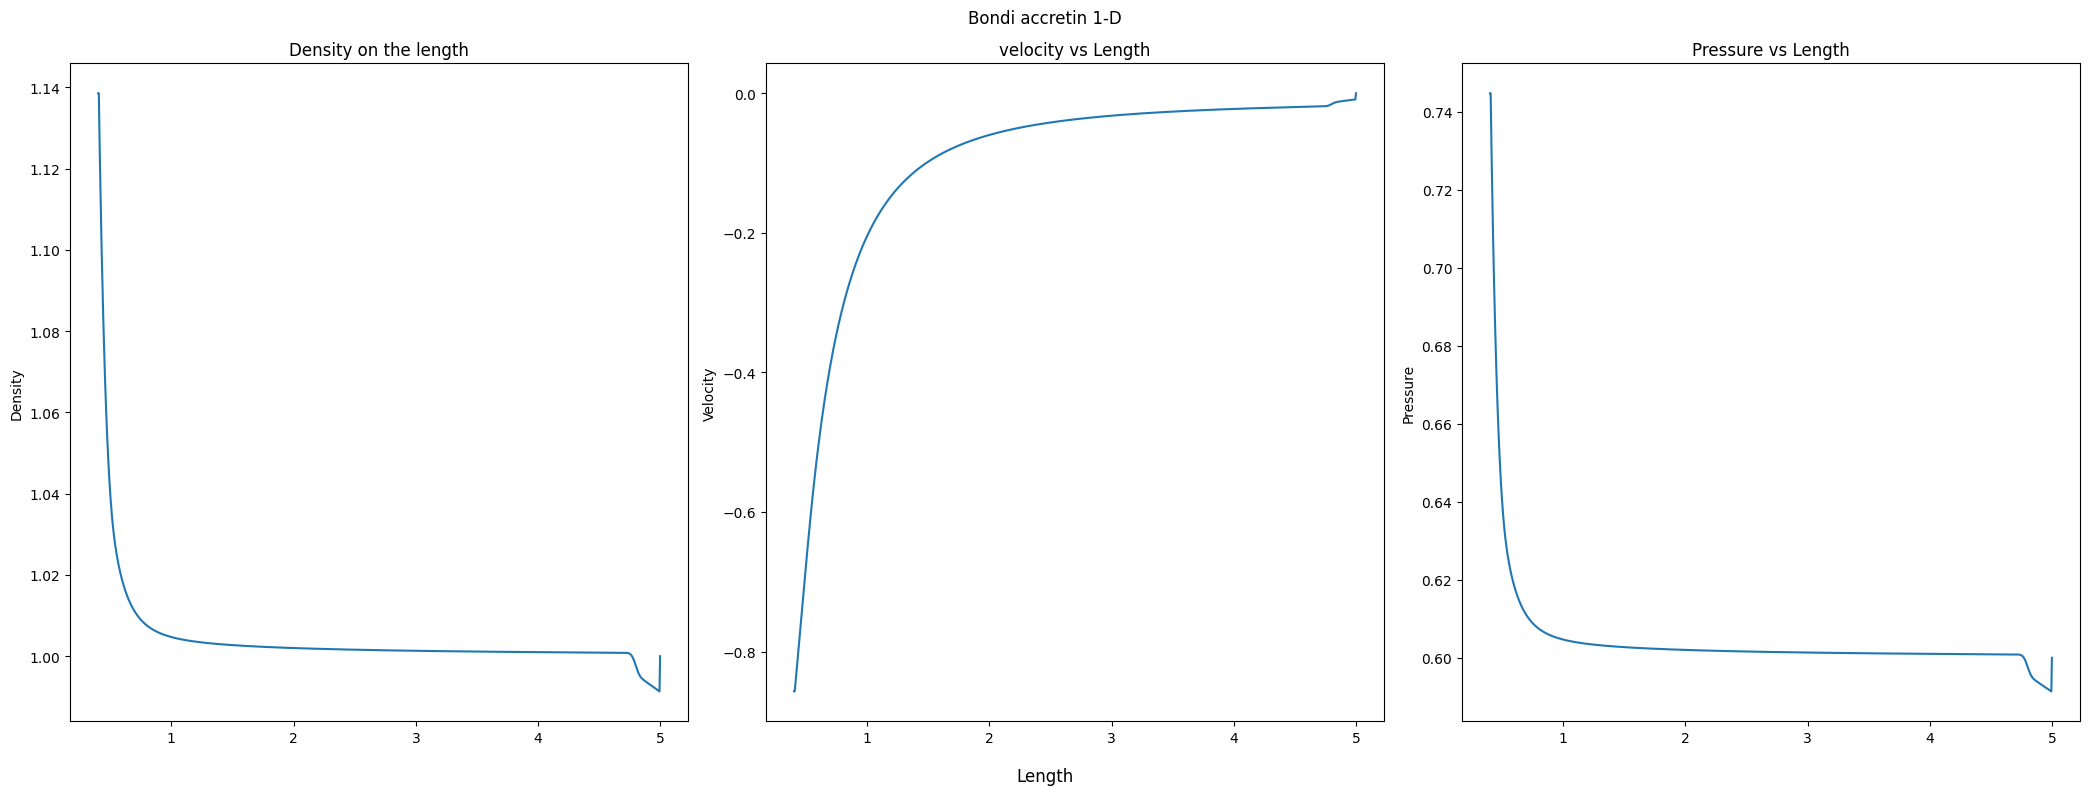

In [10]:
rho, u, p= Initial_variables(U)
fig,ax=plt.subplots(1, 3, figsize=(21, 8), sharex=True)

ax[0].plot(r, rho)
ax[0].set_ylabel("Density")
ax[0].set_title("Density on the length")

ax[1].plot(r, u)
ax[1].set_ylabel("Velocity")
ax[1].set_title("velocity vs Length")

ax[2].plot(r, p)
ax[2].set_ylabel("Pressure")
ax[2].set_title("Pressure vs Length")
fig.supxlabel("Length")

fig.suptitle("Bondi accretin 1-D")
fig.tight_layout()
plt.show()